In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Data Science Environment Ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Data Science Environment Ready!
Pandas version: 2.3.3
NumPy version: 2.3.5


In [20]:
data = {
    "Product": ["Laptop", "Mouse", "Keyboard", "Monitor",
                "Laptop", "Mouse", "Monitor", "Keyboard"],
    "Category": ["Electronics", "Accessories", "Accessories",
                 "Electronics", "Electronics", "Accessories",
                 "Electronics", "Accessories"],
    "Quantity": [2, 10, 5, 3, 1, 8, 2, 4],
    "Price": [50000, 500, 1500, 12000, 50000, 500, 12000, 1500],
    "Region": ["West", "North", "South", "West",
               "North", "South", "East", "East"]
}

df = pd.DataFrame(data)

df["Sales"] = df["Quantity"] * df["Price"]

df.to_csv("retail_sales.csv", index=False)df.to_csv("retail_sales.csv", index=False)

df
df

,Product,Category,Quantity,Price,Region,Sales
0,Laptop,Electronics,2,50000,West,100000
1,Mouse,Accessories,10,500,North,5000
2,Keyboard,Accessories,5,1500,South,7500
3,Monitor,Electronics,3,12000,West,36000
4,Laptop,Electronics,1,50000,North,50000
5,Mouse,Accessories,8,500,South,4000
6,Monitor,Electronics,2,12000,East,24000
7,Keyboard,Accessories,4,1500,East,6000


In [6]:
print("First five rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nDataset shape:")
print(df.shape)

 

First five rows:
    Product     Category  Quantity  Price Region   Sales
0    Laptop  Electronics         2  50000   West  100000
1     Mouse  Accessories        10    500  North    5000
2  Keyboard  Accessories         5   1500  South    7500
3   Monitor  Electronics         3  12000   West   36000
4    Laptop  Electronics         1  50000  North   50000

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Product   8 non-null      object
 1   Category  8 non-null      object
 2   Quantity  8 non-null      int64 
 3   Price     8 non-null      int64 
 4   Region    8 non-null      object
 5   Sales     8 non-null      int64 
dtypes: int64(3), object(3)
memory usage: 516.0+ bytes

Dataset shape:
(8, 6)


In [5]:
print("\nColumn names:")
print(df.columns)

print("\nStatistical summary:")
print(df.describe())


Column names:
Index(['Product', 'Category', 'Quantity', 'Price', 'Region', 'Sales'], dtype='object')

Statistical summary:
        Quantity         Price          Sales
count   8.000000      8.000000       8.000000
mean    4.375000  16000.000000   29062.500000
std     3.159453  21530.708966   33269.932264
min     1.000000    500.000000    4000.000000
25%     2.000000   1250.000000    5750.000000
50%     3.500000   6750.000000   15750.000000
75%     5.750000  21500.000000   39500.000000
max    10.000000  50000.000000  100000.000000


In [7]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:")
print(df.duplicated().sum())

Missing values:
Product     0
Category    0
Quantity    0
Price       0
Region      0
Sales       0
dtype: int64
Duplicate rows:
0


In [8]:
clean_df = df.copy()

clean_df = clean_df.drop_duplicates()

clean_df["Product"] = clean_df["Product"].str.strip()

clean_df["Sales"] = clean_df["Quantity"] * clean_df["Price"]

print(clean_df)

    Product     Category  Quantity  Price Region   Sales
0    Laptop  Electronics         2  50000   West  100000
1     Mouse  Accessories        10    500  North    5000
2  Keyboard  Accessories         5   1500  South    7500
3   Monitor  Electronics         3  12000   West   36000
4    Laptop  Electronics         1  50000  North   50000
5     Mouse  Accessories         8    500  South    4000
6   Monitor  Electronics         2  12000   East   24000
7  Keyboard  Accessories         4   1500   East    6000


In [9]:
# Select specific columns
print(clean_df[["Product", "Sales"]])

# Find sales greater than ₹10,000
print(clean_df[clean_df["Sales"] > 10000])

# Sort from highest to lowest sales
print(clean_df.sort_values("Sales", ascending=False))

# Select only electronics
print(clean_df[clean_df["Category"] == "Electronics"])

    Product   Sales
0    Laptop  100000
1     Mouse    5000
2  Keyboard    7500
3   Monitor   36000
4    Laptop   50000
5     Mouse    4000
6   Monitor   24000
7  Keyboard    6000
   Product     Category  Quantity  Price Region   Sales
0   Laptop  Electronics         2  50000   West  100000
3  Monitor  Electronics         3  12000   West   36000
4   Laptop  Electronics         1  50000  North   50000
6  Monitor  Electronics         2  12000   East   24000
    Product     Category  Quantity  Price Region   Sales
0    Laptop  Electronics         2  50000   West  100000
4    Laptop  Electronics         1  50000  North   50000
3   Monitor  Electronics         3  12000   West   36000
6   Monitor  Electronics         2  12000   East   24000
2  Keyboard  Accessories         5   1500  South    7500
7  Keyboard  Accessories         4   1500   East    6000
1     Mouse  Accessories        10    500  North    5000
5     Mouse  Accessories         8    500  South    4000
   Product     Category  Qu

#### Exercise 5: Perform basic data analysis

In [13]:
total_sales = clean_df["Sales"].sum()
total_quantity = clean_df["Quantity"].sum()
average_sales = clean_df["Sales"].mean()
highest_sale = clean_df["Sales"].max()

print("Total Sales: ₹", total_sales)
print("Total Quantity Sold:", total_quantity)
print("Average Sales per Row: ₹", round(average_sales, 2))
print("Highest Sale: ₹", highest_sale)

Total Sales: ₹ 232500
Total Quantity Sold: 35
Average Sales per Row: ₹ 29062.5
Highest Sale: ₹ 100000


In [14]:
# Find sales by region:
region_sales = clean_df.groupby("Region")["Sales"].sum()

print(region_sales)


Region
East      30000
North     55000
South     11500
West     136000
Name: Sales, dtype: int64


In [15]:
# Find sales by category:
category_sales = clean_df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Accessories     22500
Electronics    210000
Name: Sales, dtype: int64


#### Bar chart — Sales by product

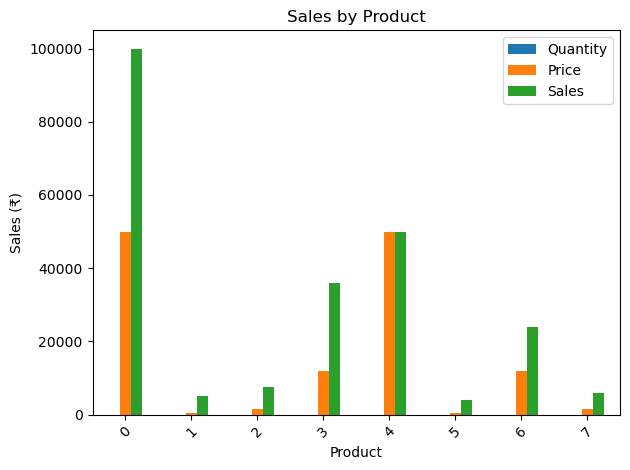

In [21]:
clean_df.plot(kind="bar")
plt.title("Sales by Product")
plt.xlabel("Product")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

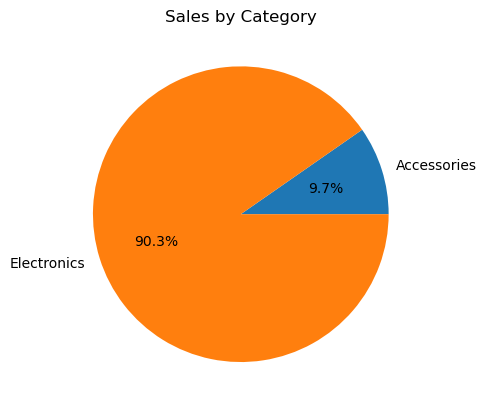

In [22]:
category_sales.plot(
    kind="pie",
    autopct="%1.1f%%"
)
plt.title("Sales by Category")
plt.ylabel("")
plt.show()

## Correlation analysis

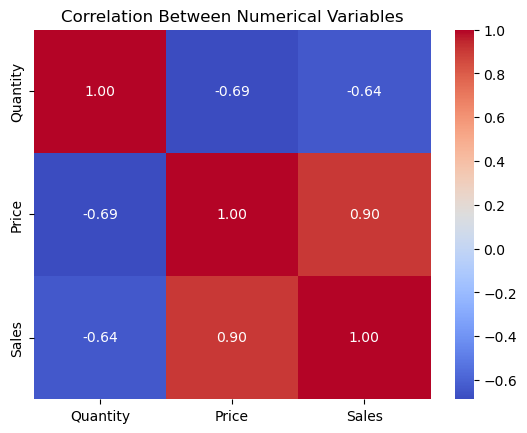

In [24]:
numeric_df = clean_df[
    ["Quantity", "Price", "Sales"]
]

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

# Save the cleaned dataset

In [25]:
clean_df.to_csv("cleaned_retail_sales.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [26]:
check_df = pd.read_csv("cleaned_retail_sales.csv")

print(check_df.head())
print("Rows and columns:", check_df.shape)

    Product     Category  Quantity  Price Region   Sales
0    Laptop  Electronics         2  50000   West  100000
1     Mouse  Accessories        10    500  North    5000
2  Keyboard  Accessories         5   1500  South    7500
3   Monitor  Electronics         3  12000   West   36000
4    Laptop  Electronics         1  50000  North   50000
Rows and columns: (8, 6)
